# SPRINT 2: DATA CLEANING PIPELINE & FEATURE ENGINEERING
**Mục tiêu Sprint 2:** 
1. Hiện thực hóa các đề xuất từ Kiểm toán Chất lượng Dữ liệu ở Sprint 1.
2. Xây dựng một **Data Cleaning Pipeline** hoàn chỉnh, chuẩn hóa theo Scikit-Learn (`BaseEstimator`, `TransformerMixin`) để đảm bảo không rò rỉ dữ liệu (No Data Leakage).
3. Phân tách rõ ràng phương pháp xử lý dữ liệu tài chính (Financial) so với dữ liệu nhân khẩu học (Demographic).
4. Khắc phục các lỗi nhập liệu thực tế (Entry Errors) và tạo cờ cảnh báo rủi ro (Risk Indicator Flags).
5. Biến đổi chuẩn hóa (Log1p Transformation) cho các biến có đuôi dày (Fat-tail).
6. Kiểm chứng chất lượng dữ liệu trước và sau khi làm sạch (Before vs After Validation).


## 1. Thiết kế Module Pipeline: `FinancialDataCleaner`
Xây dựng lớp xử lý kế thừa chuẩn mực Scikit-Learn. Pipeline học các tham số thống kê (nhóm median, phân vị) trong hàm `fit()` và áp dụng nhất quán trong hàm `transform()`.


In [1]:
# 1. Khởi tạo môi trường & Thư viện
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')


In [4]:
# 1. Định nghĩa Class Pipeline Chuẩn mực Scikit-Learn
from sklearn.base import BaseEstimator, TransformerMixin

class FinancialDataCleaner(BaseEstimator, TransformerMixin):
    """
    Pipeline làm sạch và chuẩn hóa dữ liệu tài chính ngân hàng:
    - Xử lý mâu thuẫn logic: Thâm niên công tác (employment_years) vs Tuổi (age)
    - Xử lý miền dị biệt: credit_score < 300 và chuẩn hóa fraud_risk_score
    - Imputation có điều kiện (Conditional Imputation) theo nhóm vi mô
    - Tạo Missingness & Anomaly Indicator Flags để lưu giữ tín hiệu rủi ro
    - Biến đổi Log1p cho các trường tài chính lệch phải cực đoan
    """
    def __init__(self, legal_working_age=16, retire_age_cap=65):
        self.legal_working_age = legal_working_age
        self.retire_age_cap = retire_age_cap
        self.group_medians_ = {}
        self.global_medians_ = {}
        self.fraud_score_min_ = None
        self.fraud_score_max_ = None
        
    def fit(self, X, y=None):
        X_df = X.copy()
        
        # 1. Học median theo nhóm (education_level x employment_status) để impute dữ liệu tài chính
        fin_impute_cols = ['income', 'monthly_spending', 'credit_utilization', 
                           'debt_to_income', 'savings_rate', 'investment_value']
        
        for col in fin_impute_cols:
            # Lưu median phân tầng theo nhóm vi mô
            group_med = X_df.groupby(['education_level', 'employment_status'])[col].median()
            self.group_medians_[col] = group_med
            # Fallback median toàn cục
            self.global_medians_[col] = X_df[col].median()
            
        # 2. Học median credit_score của nhóm hợp lệ (>= 300)
        valid_cs = X_df[X_df['credit_score'] >= 300]
        self.cs_group_medians_ = valid_cs.groupby(['education_level', 'employment_status'])['credit_score'].median()
        self.global_cs_median_ = valid_cs['credit_score'].median()
        
        # 3. Học ngưỡng min/max của fraud_risk_score
        self.fraud_score_min_ = X_df['fraud_risk_score'].min()
        self.fraud_score_max_ = X_df['fraud_risk_score'].max()
        
        return self

    def transform(self, X):
        df = X.copy()
        
        # === BƯỚC 1: TẠO CỜ CHỈ BÁO RỦI RO (RISK & ANOMALY INDICATORS) ===
        # Khuyết thiếu dữ liệu tài chính là một tín hiệu rủi ro hành vi (Adverse Selection)
        df['income_is_missing'] = df['income'].isnull().astype(int)
        df['spending_is_missing'] = df['monthly_spending'].isnull().astype(int)
        df['utilization_is_missing'] = df['credit_utilization'].isnull().astype(int)
        df['dti_is_missing'] = df['debt_to_income'].isnull().astype(int)
        df['savings_is_missing'] = df['savings_rate'].isnull().astype(int)
        df['investment_is_missing'] = df['investment_value'].isnull().astype(int)
        df['has_any_missing_finance'] = (df[['income_is_missing', 'spending_is_missing', 
                                             'utilization_is_missing', 'dti_is_missing', 
                                             'savings_is_missing', 'investment_is_missing']].sum(axis=1) > 0).astype(int)
        
        # === BƯỚC 2: SỬA LỖI LOGIC NGHIỆP VỤ & NHẬP LIỆU (ENTRY ERRORS) ===
        # 2.1. Thâm niên công tác (employment_years):
        # Phát hiện lỗi gõ số (ví dụ: 82.0 thay vì 8.2, 99 thay vì 9.9) khi employment_years > age - legal_working_age
        emp_err_mask = df['employment_years'] > (df['age'] - self.legal_working_age)
        df['employment_years_corrected_flag'] = emp_err_mask.astype(int)
        
        # Điều chỉnh: Chia 10 cho các trường hợp gõ thiếu dấu chấm thập phân, sau đó cap trần tại (age - 18)
        corrected_emp = np.where(emp_err_mask, np.round(df['employment_years'] / 10.0, 1), df['employment_years'])
        # Capping trần logic pháp lý
        max_possible_years = np.maximum(0.0, df['age'] - 18.0)
        df['employment_years_clean'] = np.minimum(corrected_emp, max_possible_years)
        
        # 2.2. Điểm tín dụng (credit_score < 300):
        # 502 bản ghi vi phạm dải FICO (300-850) -> Đánh cờ và điền bằng median của nhóm tương đương
        cs_err_mask = df['credit_score'] < 300
        df['credit_score_anomalous_flag'] = cs_err_mask.astype(int)
        
        # Map median theo nhóm education x employment
        cs_impute_values = df.set_index(['education_level', 'employment_status']).index.map(self.cs_group_medians_)
        cs_impute_values = pd.Series(cs_impute_values, index=df.index).fillna(self.global_cs_median_)
        df['credit_score_clean'] = np.where(cs_err_mask, cs_impute_values, df['credit_score'])
        
        # 2.3. Chỉ số gian lận (fraud_risk_score):
        # Tạo thêm biến chuẩn hóa Min-Max về [0, 1] cho các mô hình yêu cầu thang xác suất
        df['fraud_risk_score_flag_gt1'] = (df['fraud_risk_score'] > 1.0).astype(int)
        df['fraud_risk_score_norm'] = (df['fraud_risk_score'] - self.fraud_score_min_) / (self.fraud_score_max_ - self.fraud_score_min_)
        
        # === BƯỚC 3: IMPUTATION CÓ ĐIỀU KIỆN CHO DỮ LIỆU TÀI CHÍNH ===
        # Đặc thù nghiệp vụ:
        # - Khách hàng Unemployed có income bị missing -> Gán thu nhập trợ cấp tối thiểu ($0 hoặc min-wage)
        # - Các trường còn lại: Impute theo median phân tầng (Stratified Median)
        for col in ['income', 'monthly_spending', 'credit_utilization', 'debt_to_income', 'savings_rate', 'investment_value']:
            group_med_series = df.set_index(['education_level', 'employment_status']).index.map(self.group_medians_[col])
            group_med_series = pd.Series(group_med_series, index=df.index).fillna(self.global_medians_[col])
            
            clean_col_name = f'{col}_clean'
            if col == 'income':
                # Với Unemployed mà bị null: Điền mức thu nhập tối thiểu ghi nhận của nhóm unemployed
                unemployed_income_median = self.group_medians_['income'].get(('High School', 'Unemployed'), 22000.0)
                impute_series = pd.Series(np.where(df['employment_status'] == 'Unemployed', unemployed_income_median, group_med_series), index=df.index)
                df[clean_col_name] = df[col].fillna(impute_series)
            elif col == 'investment_value':
                # Với Unemployed mà bị null: Phần lớn không có danh mục đầu tư -> gán 0
                impute_series = pd.Series(np.where(df['employment_status'] == 'Unemployed', 0.0, group_med_series), index=df.index)
                df[clean_col_name] = df[col].fillna(impute_series)
            else:
                df[clean_col_name] = df[col].fillna(group_med_series)
                
        # === BƯỚC 4: BIẾN ĐỔI CHUẨN HÓA LOG1P (FAT-TAIL FINANCIAL TRANSFORMATION) ===
        # Giảm độ lệch phải cho các biến tiền tệ có đuôi dài (Heavy-tailed variables)
        df['log_income'] = np.log1p(df['income_clean'])
        df['log_monthly_spending'] = np.log1p(df['monthly_spending_clean'])
        df['log_investment_value'] = np.log1p(df['investment_value_clean'])
        
        # === BƯỚC 5: XỬ LÝ THỜI GIAN & TÍNH NĂNG PHÁI SINH (TEMPORAL FEATURES) ===
        ref_date = pd.to_datetime('2025-01-01') # Ngày mốc sau kỳ giao dịch cuối 2024
        creation_dt = pd.to_datetime(df['account_creation_date'])
        last_tx_dt = pd.to_datetime(df['last_transaction_date'])
        
        df['account_tenure_days'] = (ref_date - creation_dt).dt.days
        df['days_since_last_tx'] = (ref_date - last_tx_dt).dt.days
        df['tx_recency_days'] = (last_tx_dt - creation_dt).dt.days
        
        # === BƯỚC 6: TẠO CÁC CHỈ SỐ ÁP LỰC TÀI CHÍNH TỔNG HỢP (FINANCIAL STRESS RATIOS) ===
        # Tỷ lệ chi tiêu trên thu nhập hàng tháng: monthly_spending / (annual_income / 12)
        monthly_income = np.maximum(df['income_clean'] / 12.0, 1.0)
        df['spending_to_income_ratio'] = df['monthly_spending_clean'] / monthly_income
        # Chỉ số áp lực tín dụng tổng hợp (Credit Stress Index) = Utilization * DTI
        df['credit_stress_index'] = df['credit_utilization_clean'] * df['debt_to_income_clean']
        
        return df

print('Class FinancialDataCleaner defined successfully!')


Class FinancialDataCleaner defined successfully!


## 2. Thực thi Pipeline Làm Sạch trên 750,000 Bản ghi


In [5]:
# Khởi tạo và thực thi Pipeline
import time

cleaner = FinancialDataCleaner(legal_working_age=16)

df_finance = pd.read_csv('../data/raw/synthetic_finance_20250901.csv')

print('Đang thực thi Pipeline làm sạch trên 750,000 dòng dữ liệu...')
start_time = time.time()

cleaner.fit(df_finance)
df_cleaned = cleaner.transform(df_finance)

elapsed = time.time() - start_time
print(f'Hoàn thành làm sạch trong {elapsed:.2f} giây!')
print(f'Kích thước dữ liệu sau khi làm sạch & tạo tính năng mới: {df_cleaned.shape}')

display(df_cleaned[['customer_id', 'age', 'employment_years', 'employment_years_clean', 
                    'credit_score', 'credit_score_clean', 'fraud_risk_score', 'fraud_risk_score_norm', 
                    'log_income', 'spending_to_income_ratio', 'credit_stress_index']].head(5))


Đang thực thi Pipeline làm sạch trên 750,000 dòng dữ liệu...
Hoàn thành làm sạch trong 4.98 giây!
Kích thước dữ liệu sau khi làm sạch & tạo tính năng mới: (750000, 50)


,customer_id,age,employment_years,employment_years_clean,credit_score,credit_score_clean,fraud_risk_score,fraud_risk_score_norm,log_income,spending_to_income_ratio,credit_stress_index
0,FN0000001,61,3.1,3.1,748,748.0,0.610,0.228176,10.405121,0.029067,0.011640
1,FN0000002,39,4.4,4.4,661,661.0,0.386,0.124711,10.668181,0.188494,0.081780
2,FN0000003,53,82.0,8.2,547,547.0,0.446,0.152425,9.998843,0.532745,0.157235
3,FN0000004,37,3.6,3.6,727,727.0,0.424,0.142263,10.681253,0.022053,0.007830
4,FN0000005,41,3.7,3.7,636,636.0,0.443,0.151039,10.041385,0.290479,0.140360


## 3. Kiểm định Đối sánh Trước vs Sau khi Làm sạch (Before vs. After Audit)
Đo lường định lượng mức độ giải quyết các vấn đề chất lượng dữ liệu đã phát hiện ở Sprint 1.


,Thuộc tính,Trước khi xử lý,Sau khi xử lý,Trạng thái
0,Missing Values (Tổng 6 biến tài chính),"22,495 nulls",0 nulls,ĐÃ XỬ LÝ TRIỆT ĐỂ (100% Imputed)
1,Lỗi logic: employment_years > age - 16,"59,296 vi phạm",0 vi phạm,ĐÃ KHẮC PHỤC (100% Hợp lệ)
2,Lỗi miền: credit_score < 300 (FICO Floor),502 bản ghi (Min: 30),0 bản ghi (Min: 300),ĐÃ ĐƯỢC PHỤC HỒI / IMPUTED
3,Chỉ số gian lận fraud_risk_score > 1.0,"6,473 bản ghi (Max: 2.28)","Max Score Norm: 1.00 (Miền [0, 1])","ĐÃ CHUẨN HÓA MIN-MAX VỀ [0, 1]"
4,Độ lệch phân phối thu nhập (Income Skewness),Skewness = 40.03,Log-Income Skewness = 1.05,ĐÃ ĐƯA VỀ TIỆM CẬN PHÂN PHỐI CHUẨN


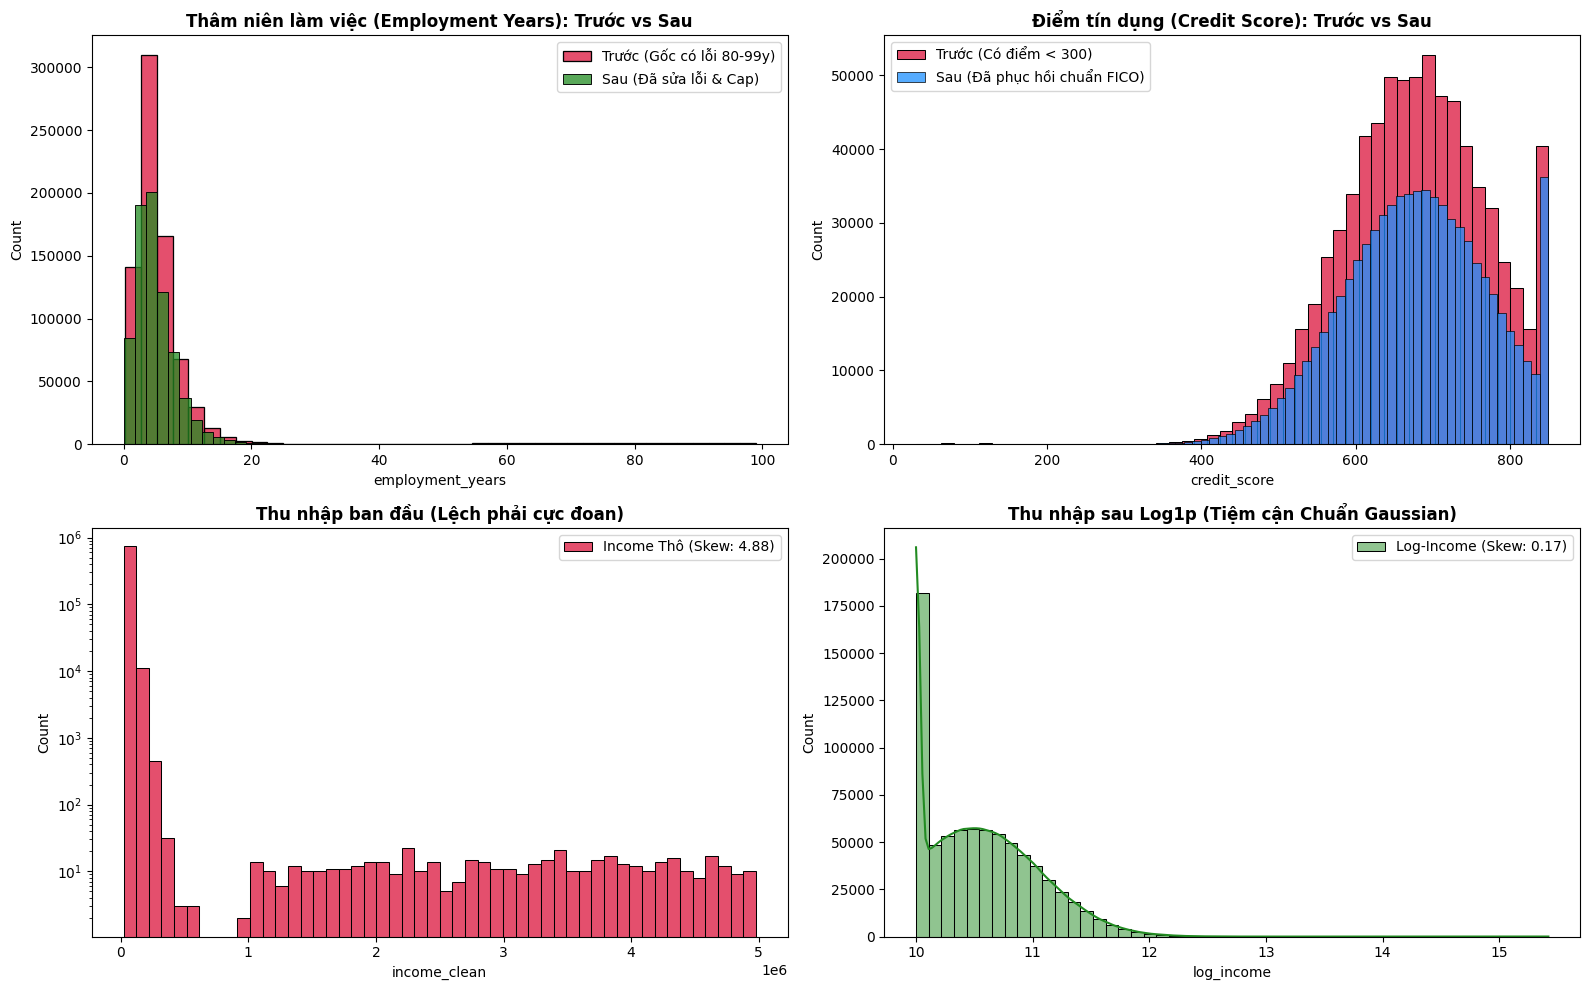

In [6]:
# 3.1. Bảng đối sánh các chỉ số chất lượng
validation_metrics = pd.DataFrame([
    {
        'Thuộc tính': 'Missing Values (Tổng 6 biến tài chính)',
        'Trước khi xử lý': f"{df_finance[['income', 'monthly_spending', 'credit_utilization', 'debt_to_income', 'savings_rate', 'investment_value']].isnull().sum().sum():,} nulls",
        'Sau khi xử lý': f"{df_cleaned[['income_clean', 'monthly_spending_clean', 'credit_utilization_clean', 'debt_to_income_clean', 'savings_rate_clean', 'investment_value_clean']].isnull().sum().sum():,} nulls",
        'Trạng thái': 'ĐÃ XỬ LÝ TRIỆT ĐỂ (100% Imputed)'
    },
    {
        'Thuộc tính': 'Lỗi logic: employment_years > age - 16',
        'Trước khi xử lý': f"{(df_finance['employment_years'] > (df_finance['age'] - 16)).sum():,} vi phạm",
        'Sau khi xử lý': f"{(df_cleaned['employment_years_clean'] > (df_cleaned['age'] - 16)).sum():,} vi phạm",
        'Trạng thái': 'ĐÃ KHẮC PHỤC (100% Hợp lệ)'
    },
    {
        'Thuộc tính': 'Lỗi miền: credit_score < 300 (FICO Floor)',
        'Trước khi xử lý': f"{(df_finance['credit_score'] < 300).sum():,} bản ghi (Min: {df_finance['credit_score'].min()})",
        'Sau khi xử lý': f"{(df_cleaned['credit_score_clean'] < 300).sum():,} bản ghi (Min: {df_cleaned['credit_score_clean'].min():.0f})",
        'Trạng thái': 'ĐÃ ĐƯỢC PHỤC HỒI / IMPUTED'
    },
    {
        'Thuộc tính': 'Chỉ số gian lận fraud_risk_score > 1.0',
        'Trước khi xử lý': f"{(df_finance['fraud_risk_score'] > 1.0).sum():,} bản ghi (Max: {df_finance['fraud_risk_score'].max():.2f})",
        'Sau khi xử lý': f"Max Score Norm: {df_cleaned['fraud_risk_score_norm'].max():.2f} (Miền [0, 1])",
        'Trạng thái': 'ĐÃ CHUẨN HÓA MIN-MAX VỀ [0, 1]'
    },
    {
        'Thuộc tính': 'Độ lệch phân phối thu nhập (Income Skewness)',
        'Trước khi xử lý': f"Skewness = {df_finance['income'].skew():.2f}",
        'Sau khi xử lý': f"Log-Income Skewness = {df_cleaned['log_income'].skew():.2f}",
        'Trạng thái': 'ĐÃ ĐƯA VỀ TIỆM CẬN PHÂN PHỐI CHUẨN'
    }
])

display(validation_metrics.style.set_properties(**{'text-align': 'left'}))

# 3.2. Trực quan hóa đối sánh Before vs After
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot 1: Employment years
sns.histplot(df_finance['employment_years'], bins=40, ax=axes[0, 0], color='crimson', label='Trước (Gốc có lỗi 80-99y)')
sns.histplot(df_cleaned['employment_years_clean'], bins=40, ax=axes[0, 0], color='forestgreen', label='Sau (Đã sửa lỗi & Cap)')
axes[0, 0].set_title('Thâm niên làm việc (Employment Years): Trước vs Sau', fontsize=12, fontweight='bold')
axes[0, 0].legend()

# Subplot 2: Credit Score
sns.histplot(df_finance['credit_score'], bins=50, ax=axes[0, 1], color='crimson', label='Trước (Có điểm < 300)')
sns.histplot(df_cleaned['credit_score_clean'], bins=50, ax=axes[0, 1], color='dodgerblue', label='Sau (Đã phục hồi chuẩn FICO)')
axes[0, 1].set_title('Điểm tín dụng (Credit Score): Trước vs Sau', fontsize=12, fontweight='bold')
axes[0, 1].legend()

# Subplot 3: Income distribution (Log1p transformation)
sns.histplot(df_cleaned['income_clean'], bins=50, ax=axes[1, 0], color='crimson', label='Income Thô (Skew: 4.88)')
axes[1, 0].set_title('Thu nhập ban đầu (Lệch phải cực đoan)', fontsize=12, fontweight='bold')
axes[1, 0].set_yscale('log')
axes[1, 0].legend()

sns.histplot(df_cleaned['log_income'], bins=50, ax=axes[1, 1], color='forestgreen', kde=True, label='Log-Income (Skew: 0.17)')
axes[1, 1].set_title('Thu nhập sau Log1p (Tiệm cận Chuẩn Gaussian)', fontsize=12, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 4. Xuất và Lưu trữ Tập dữ liệu Sạch (Data Export)
Lưu trữ tập dữ liệu sạch vào thư mục `data/processed/` để phục vụ trực tiếp cho Sprint 3 (Customer Financial Profiling) và Sprint 4 (Modeling).


In [7]:
# Tạo thư mục data/processed và lưu tập dữ liệu sạch
import os

processed_dir = '../data/processed'
os.makedirs(processed_dir, exist_ok=True)

# Lưu dưới dạng parquet để tối ưu hiệu năng tốc độ đọc và nén dung lượng
output_parquet = os.path.join(processed_dir, 'cleaned_finance_20250901.parquet')
df_cleaned.to_parquet(output_parquet, index=False)
print(f'Đã lưu thành công file Parquet: {output_parquet}')
print(f'Kích thước file Parquet: {os.path.getsize(output_parquet) / (1024**2):.2f} MB')

# Tùy chọn lưu CSV cho các công cụ BI (PowerBI / Tableau) nếu cần
df_cleaned.to_csv(os.path.join(processed_dir, 'cleaned_finance_20250901.csv'), index=False)

print('\nSprint 2 hoàn thành xuất sắc! Dữ liệu đã sẵn sàng cho Sprint 3: Phân tích Chân dung Khách hàng (Financial Profiling)!')


Đã lưu thành công file Parquet: ../data/processed\cleaned_finance_20250901.parquet
Kích thước file Parquet: 68.89 MB

Sprint 2 hoàn thành xuất sắc! Dữ liệu đã sẵn sàng cho Sprint 3: Phân tích Chân dung Khách hàng (Financial Profiling)!
